In [10]:
import matplotlib.pyplot as plt
import numpy as np

from mpl_toolkits.basemap import Basemap

import xarray as xr
import pandas as pd
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.colors as colors

from mpl_toolkits.axes_grid1 import AxesGrid
from mpl_toolkits.basemap import Basemap

In [12]:

ds1 = xr.open_dataset('/media/athira/One Touch/final_datasets/Review/Edited_plots/merged_files/pH_ensemble_ssp585_merged_r1.nc').squeeze()
ds2 = xr.open_dataset('/media/athira/One Touch/final_datasets/Review/Edited_plots/merged_files/pH_ensemble_ssp245_merged_r1.nc').squeeze()
ds3 = xr.open_dataset('/media/athira/One Touch/final_datasets/Review/Edited_plots/merged_files/pH_ensemble_ssp126_merged_r1.nc').squeeze()

lat_range = slice(-30, 30)  # Latitude range from -30 to 30
lon_range = slice(30, 120)  # Longitude range from 30 to 100

pH_Hist  = ds1.sel(lat=lat_range, lon=lon_range, time=slice('1985', '2014')).groupby('time.month').mean()

pH_NF = ds1.sel(lat=lat_range, lon=lon_range, time=slice('2015', '2040')).groupby('time.month').mean()
pH_MF = ds1.sel(lat=lat_range, lon=lon_range, time=slice('2041', '2070')).groupby('time.month').mean()
pH_FF = ds1.sel(lat=lat_range, lon=lon_range, time=slice('2071', '2100')).groupby('time.month').mean()

pH_Hist_245  = ds1.sel(lat=lat_range, lon=lon_range, time=slice('1985', '2014')).groupby('time.month').mean()
pH_NF_245 = ds2.sel(lat=lat_range, lon=lon_range, time=slice('2015', '2040')).groupby('time.month').mean()
pH_MF_245 = ds2.sel(lat=lat_range, lon=lon_range, time=slice('2041', '2070')).groupby('time.month').mean()
pH_FF_245 = ds2.sel(lat=lat_range, lon=lon_range, time=slice('2071', '2100')).groupby('time.month').mean()

pH_Hist_126  = ds1.sel(lat=lat_range, lon=lon_range, time=slice('1985', '2014')).groupby('time.month').mean()
pH_NF_126 = ds3.sel(lat=lat_range, lon=lon_range, time=slice('2015', '2040')).groupby('time.month').mean()
pH_MF_126  = ds3.sel(lat=lat_range, lon=lon_range, time=slice('2041', '2070')).groupby('time.month').mean()
pH_FF_126  = ds3.sel(lat=lat_range, lon=lon_range, time=slice('2071', '2100')).groupby('time.month').mean()


NF_diff = pH_NF - pH_Hist
MF_diff = pH_MF - pH_Hist
FF_diff = pH_FF - pH_Hist

NF_diff_245 = pH_NF_245 - pH_Hist_245
MF_diff_245 = pH_MF_245 - pH_Hist_245
FF_diff_245 = pH_FF_245 - pH_Hist_245

NF_diff_126 = pH_NF_126 - pH_Hist_126
MF_diff_126 = pH_MF_126 - pH_Hist_126
FF_diff_126 = pH_FF_126 - pH_Hist_126

NF_diff = NF_diff.mean('month')
MF_diff = MF_diff.mean('month')
FF_diff = FF_diff.mean('month')

NF_diff_245 = NF_diff_245.mean('month')
MF_diff_245 = MF_diff_245.mean('month')
FF_diff_245 = FF_diff_245.mean('month')


NF_diff_126 = NF_diff_126.mean('month')
MF_diff_126 = MF_diff_126.mean('month')
FF_diff_126 = FF_diff_126.mean('month')



In [13]:
ds1=xr.open_dataset('Total_STL_ssp585_NF_r2.nc')
ds2=xr.open_dataset('Total_STL_ssp585_MF_r2.nc')
ds3=xr.open_dataset('Total_STL_ssp585_FF_r2.nc')


ds4=xr.open_dataset('Total_STL_ssp245_NF_r2.nc')
ds5=xr.open_dataset('Total_STL_ssp245_MF_r2.nc')
ds6=xr.open_dataset('Total_STL_ssp245_FF_r2.nc')

ds7=xr.open_dataset('Total_STL_ssp126_NF_r2.nc')
ds8=xr.open_dataset('Total_STL_ssp126_MF_r2.nc')
ds9=xr.open_dataset('Total_STL_ssp126_FF_r2.nc')




In [14]:
NF_585_t = abs(NF_diff)/abs(ds1)
MF_585_t = abs(MF_diff)/abs(ds2)
FF_585_t = abs(FF_diff)/abs(ds3)

NF_245_t = abs(NF_diff_245)/abs(ds4)
MF_245_t = abs(MF_diff_245)/abs(ds5)
FF_245_t = abs(FF_diff_245)/abs(ds6)

NF_126_t = abs(NF_diff_126)/abs(ds7)
MF_126_t = abs(MF_diff_126)/abs(ds8)
FF_126_t = abs(FF_diff_126)/abs(ds9)


# Plot

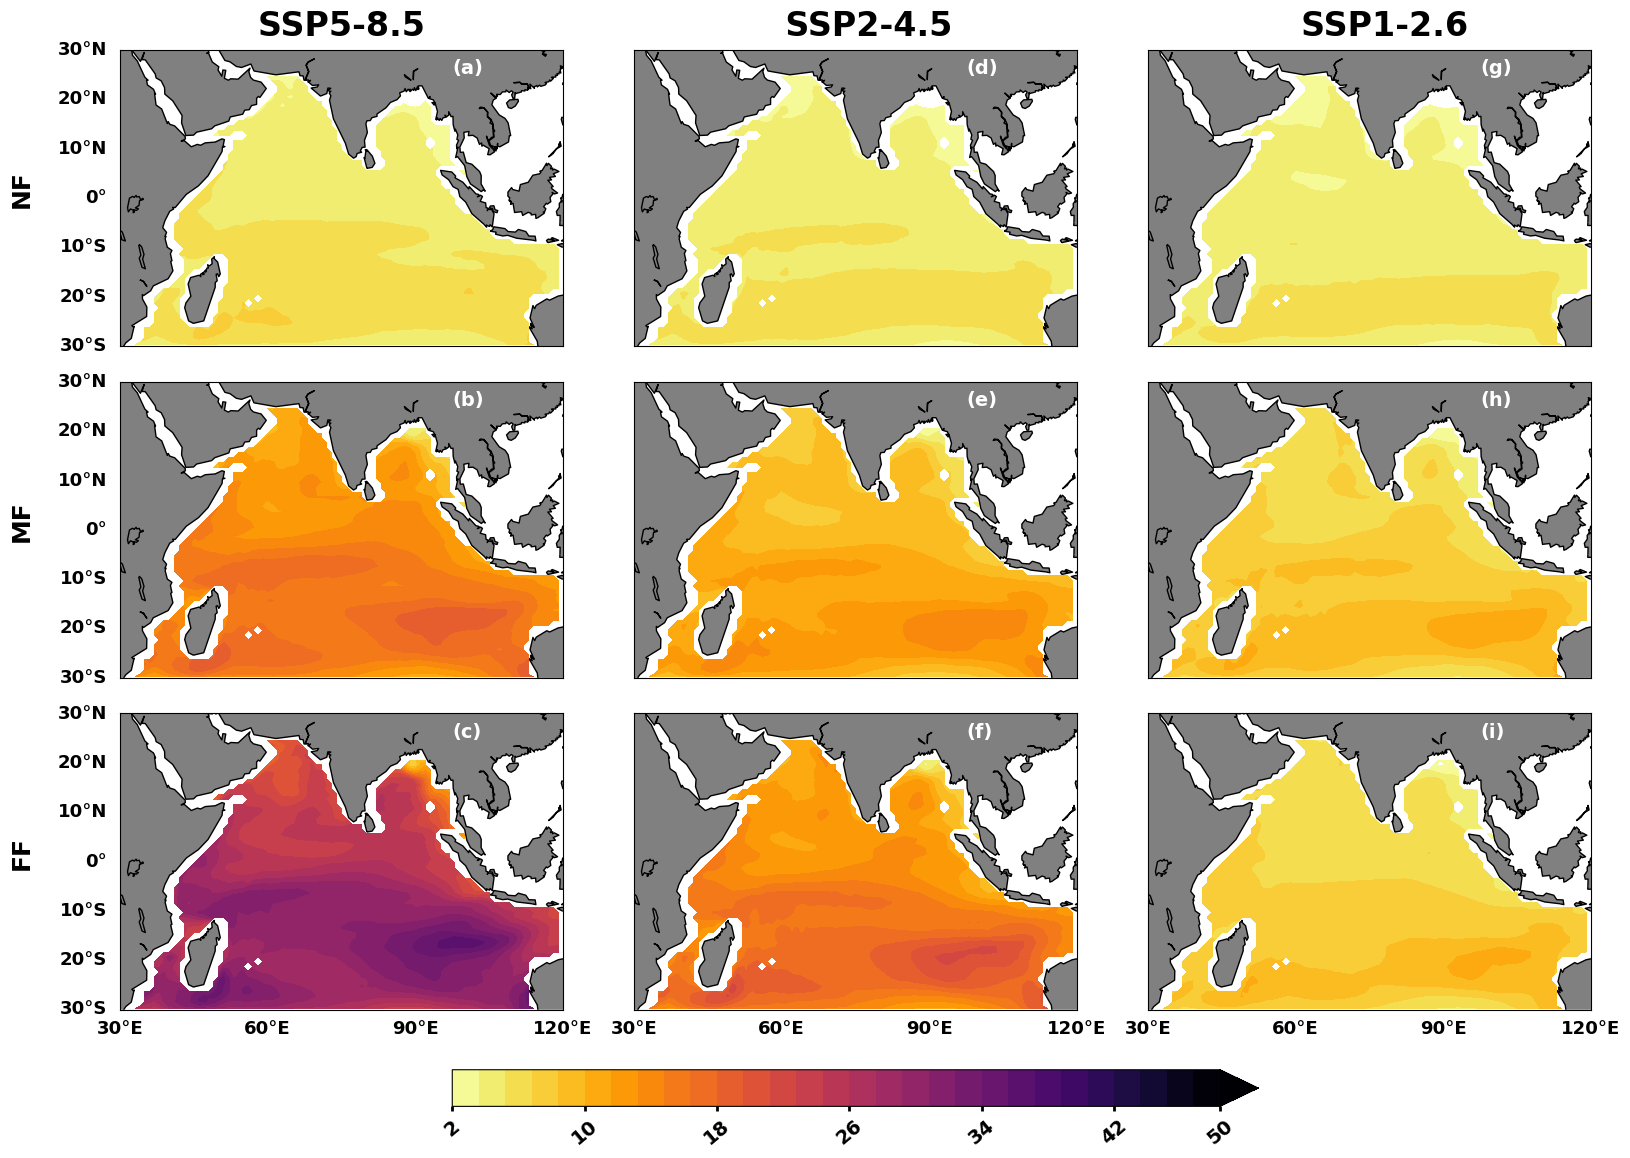

In [20]:
fig, ax = plt.subplots(nrows=3, ncols=3, sharex=True, sharey=True, figsize=(26, 20))
plt.subplots_adjust(bottom=0.2, top=0.8, left=0.13, right=0.75, wspace=-0.12, hspace=0.12)


fig.suptitle('SSP5-8.5                               SSP2-4.5                              SSP1-2.6', fontsize=24, ha= 'center', fontweight='bold',x=0.443,y=0.82)

periods = ['NF', 'MF', 'FF']
subplot_labels = ['(a)', '(d)', '(g)', '(b)', '(e)', '(h)', '(c)', '(f)', '(i)']

datasets = {
    'pH': [NF_585_t, MF_585_t, FF_585_t],
    'pH_245': [NF_245_t, MF_245_t, FF_245_t],
    'pH_126': [NF_126_t, MF_126_t, FF_126_t]
}

quad_contour_sets_pH = []
quad_contour_sets_other = []

for i, period in enumerate(periods):
    for j, (key, data_list) in enumerate(datasets.items()):
        data = data_list[i]
        ph_data = np.squeeze(data.ph)
        levels = np.arange(2, 50, 1.6)
        cmap='inferno_r'

        m = Basemap(llcrnrlat=-30.1, urcrnrlat=30.1, llcrnrlon=30, urcrnrlon=120.1, resolution='c', ax=ax[i, j])
        m.drawcoastlines()
        m.fillcontinents(color='gray', lake_color='gray')

        lon, lat = np.meshgrid(data.lon, data.lat)

        contour = m.contourf(lon, lat, ph_data, levels=levels, cmap=cmap, extend='max', zorder=10)
        
        if key == 'pH':
            quad_contour_sets_pH.append(contour)
        else:
            quad_contour_sets_other.append(contour)

# Draw latitude labels (left column)
for i in range(3):
    m = Basemap(llcrnrlat=-30.1, urcrnrlat=30.1, llcrnrlon=30, urcrnrlon=120.1, resolution='c', ax=ax[i, 0])
    m.drawparallels(range(-30, 31, 10), labels=[1, 0, 0, 0], color='w', fontsize=13, fontweight='bold', zorder=0, xoffset=2.5)

# Draw longitude labels (bottom row)
for j in range(3):
    m = Basemap(llcrnrlat=-30.1, urcrnrlat=30.1, llcrnrlon=30, urcrnrlon=120.1, resolution='c', ax=ax[2, j])
    m.drawmeridians(range(30, 121, 30), labels=[1, 0, 0, 1], color='w', fontsize=13, fontweight='bold', zorder=0, yoffset=2)

# Row titles
for i, period in enumerate(periods):
    ax[i, 0].text(-0.22, 0.53, f"{period}", rotation='vertical', fontsize=18, fontweight='bold',
                  transform=ax[i, 0].transAxes, va='center', ha='center', color='k', zorder=10)

# Subplot labels (a) to (i)
for i in range(3):
    for j in range(3):
        idx = i * 3 + j
        ax[i, j].text(0.75, 0.97, subplot_labels[idx], transform=ax[i, j].transAxes,
                      fontsize=14, fontweight='bold', va='top', ha='left', color='w')

# Colorbar 1 for first column (pH)
if quad_contour_sets_pH:
    cbar1 = fig.colorbar(quad_contour_sets_pH[0], ax=ax[:, :], pad=0.05, shrink=0.5, aspect=22,
                         orientation='horizontal', extend='max')
    cbar1.set_ticks(np.arange(2, 51, 8))
    cbar1.ax.tick_params(labelsize=14, width=2, rotation=40)
    for label in cbar1.ax.get_xticklabels():
        label.set_fontweight('bold')

    
# plt.savefig('pH_ratio_replot_review2.png', bbox_inches = 'tight', dpi = 300)

plt.show()
